In [2]:
# 도구 import
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import sys
import numpy as np
import pandas as pd
import seaborn as sns

print(f"Python Version: {sys.version}")
print(f"Numpy Version : {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Seaborn Version: {sns.__version__}")

import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


Python Version: 3.15.1 (tags/v3.15.1:c37e74c, Oct 21 2026, 06:24:08) [MSC v.1951 64 bit (AMD64)]
Numpy Version : 2.5.4
Pandas version: 3.1.0
Seaborn Version: 0.13.2


### 1. 데이터셋 변수 정의 (`Data/givemesomecredit.csv`)
- **`SeriousDlqin2yrs`** *(Target $Y$)*: 향후 2년 내 90일 이상 심각한 연체(채무불이행) 발생 여부 (`1` = 부도, `0` = 정상) — 이진 분류 타겟
- **`RevolvingUtilizationOfUnsecuredLines`**: 담보 없는 신용카드 및 개인 신용 한도 소진율 (총 잔액 / 총 한도 비율) — 수치형(연속형)
- **`age`**: 대출 신청자의 연령(세) — 수치형(정수형)
- **`NumberOfTime30-59DaysPastDueNotWorse`**: 최근 2년 간 30~59일 단기 연체 발생 횟수 — 수치형(정수형)
- **`DebtRatio`**: 월 총소득 대비 월 부채 상환액, 위자료, 생활비 지출 비율 — 수치형(연속형)
- **`MonthlyIncome`**: 월 소득 (결측치 대체 완료) — 수치형(실수형)
- **`NumberOfDependents`**: 본인을 제외한 부양가족 수 — 수치형/범주형(정수형)
- **`CombinedDefaulted`** *(파생 변수)*: 과거 30~89일 또는 90일 이상 중장기 연체 이력 통합 구간 — 이진 범주형(`0` / `1`)
- **`CombinedCreditLoans`** *(파생 변수)*: 주택담보대출을 포함한 총 개설 대출 및 신용한도 보유 구간 — 이진 범주형(`0` / `1`)

In [3]:
# 데이터 로드 및 확인
data = pd.read_csv("Data/givemesomecredit.csv")
data.head(5)
data.shape


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfDependents,CombinedDefaulted,CombinedCreditLoans
0,1,0.766127,45,2,0.802982,9120,2,1,1
1,0,0.957151,40,0,0.121876,2600,1,0,0
2,0,0.658180,38,1,0.085113,3042,0,1,0
3,0,0.233810,30,0,0.036050,3300,0,0,0
4,0,0.907239,49,1,0.024926,63588,0,1,1


(150000, 9)

In [28]:
# 기술통계, 왜도, 결측치, 타입 정리
d = data.dtypes
n = data.isnull().sum()
s = data.skew().round(3)
dn = pd.DataFrame((s, n, d), index=['skew', 'isnull', 'dtypes']).T
desc = data.describe().round(3).T
result = pd.concat([desc, dn],axis=1)
print("각 변수에 대해 기술통계 및 타입, 결측치 여부")
result

각 변수에 대해 기술통계 및 타입, 결측치 여부


,count,mean,std,min,25%,50%,75%,max,skew,isnull,dtypes
SeriousDlqin2yrs,150000.0,0.067,0.250,0.0,0.000,0.000,0.000,1.0,3.469,0,int64
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048,249.755,0.0,0.030,0.154,0.559,50708.0,97.632,0,float64
age,150000.0,52.296,14.771,21.0,41.000,52.000,63.000,109.0,0.189,0,int64
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421,4.193,0.0,0.000,0.000,0.000,98.0,22.597,0,int64
DebtRatio,150000.0,353.005,2037.819,0.0,0.175,0.367,0.868,329664.0,95.158,0,float64
MonthlyIncome,150000.0,6673.266,12880.469,0.0,3903.000,6600.000,7400.000,3008750.0,127.357,0,int64
NumberOfDependents,150000.0,0.737,1.107,0.0,0.000,0.000,1.000,20.0,1.626,0,int64
CombinedDefaulted,150000.0,0.202,0.402,0.0,0.000,0.000,0.000,1.0,1.481,0,int64
CombinedCreditLoans,150000.0,0.742,0.437,0.0,0.000,1.000,1.000,1.0,-1.109,0,int64


모든 변수에 대해 결측치가 없음은 확인됐지만, RevolvingUtilizationOfUnsecuredLines, DebtRatio, MonthlyIncome 에서 극단값으로 인해 높은 왜도를 보임을 알 수 있다.

클래스 각 분류의 개수


,count
SeriousDlqin2yrs,
0,139974
1,10026


<Axes: xlabel='SeriousDlqin2yrs'>

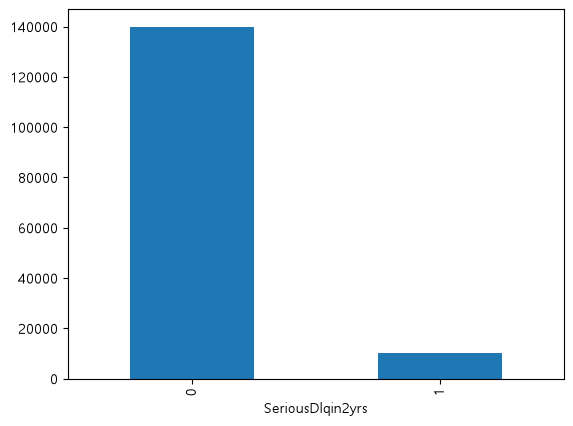

Class(SeriousDlqin2yrs) 에 대해 0(정상)과 1(부도)의 비율이 93.3:6.7, IR은 13.961로, 매우 불균형함을 보이고 있음.


In [5]:
# 클래스 분석
cls = data["SeriousDlqin2yrs"].value_counts()
print("클래스 각 분류의 개수")
cls.to_frame()
cls.plot(kind='bar')
plt.show()
dlqratio = (cls[0] / cls.sum() * 100).round(1)

print(f"Class(SeriousDlqin2yrs) 에 대해 0(정상)과 1(부도)의 비율이 {dlqratio}:{(100 - dlqratio).round(1)}, IR은 {(cls[0]/cls[1]).round(3)}로, 매우 불균형함을 보이고 있음.")


array([[<Axes: title={'center': 'SeriousDlqin2yrs'}>,
        <Axes: title={'center': 'RevolvingUtilizationOfUnsecuredLines'}>,
        <Axes: title={'center': 'age'}>],
       [<Axes: title={'center': 'NumberOfTime30-59DaysPastDueNotWorse'}>,
        <Axes: title={'center': 'DebtRatio'}>,
        <Axes: title={'center': 'MonthlyIncome'}>],
       [<Axes: title={'center': 'NumberOfDependents'}>,
        <Axes: title={'center': 'CombinedDefaulted'}>,
        <Axes: title={'center': 'CombinedCreditLoans'}>]], dtype=object)

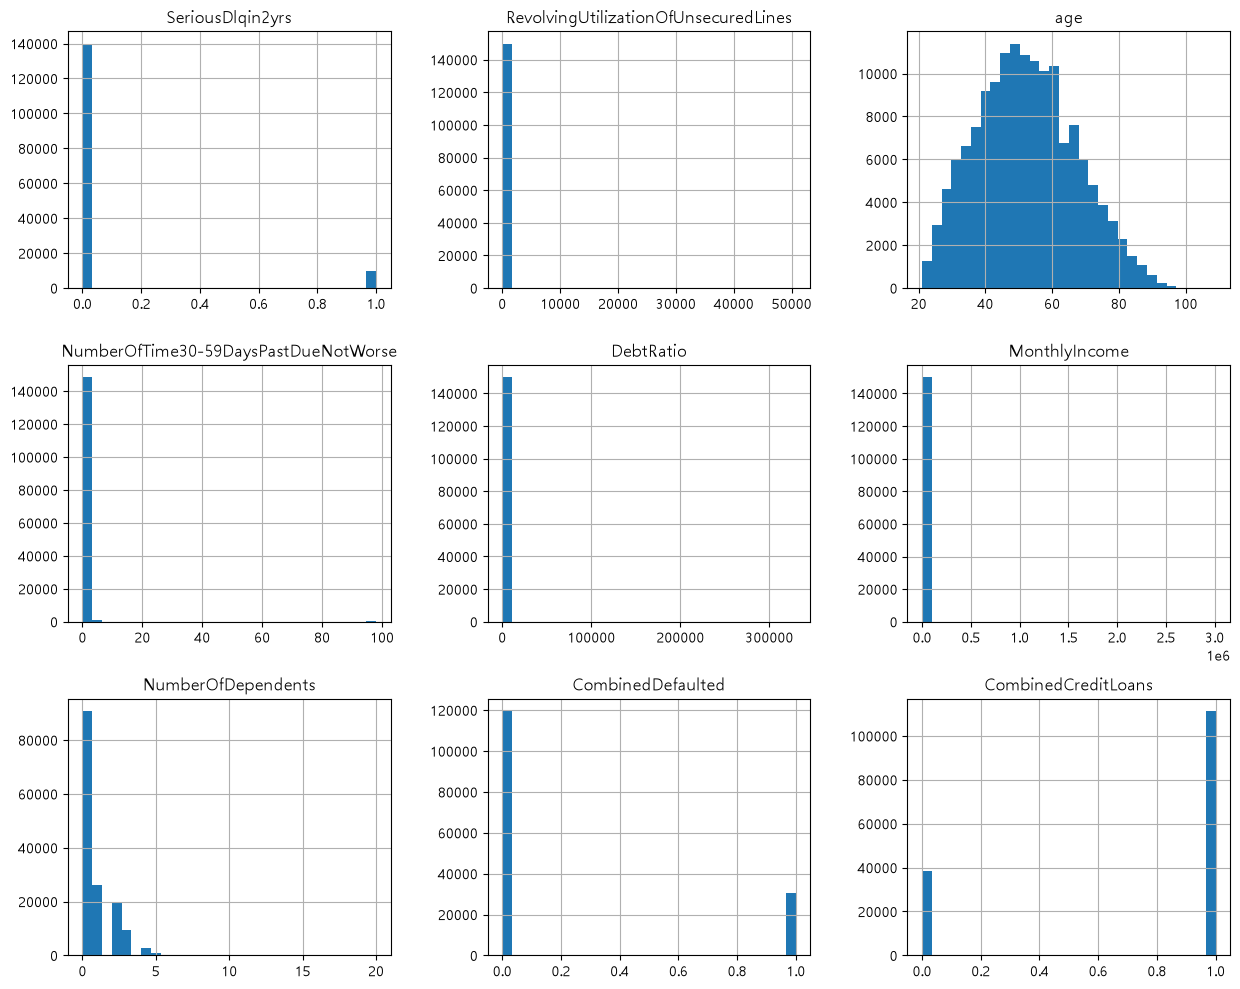

In [6]:
# 데이터 히스토그램
data.hist(figsize=(15,12), bins=30)

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>]], dtype=object)

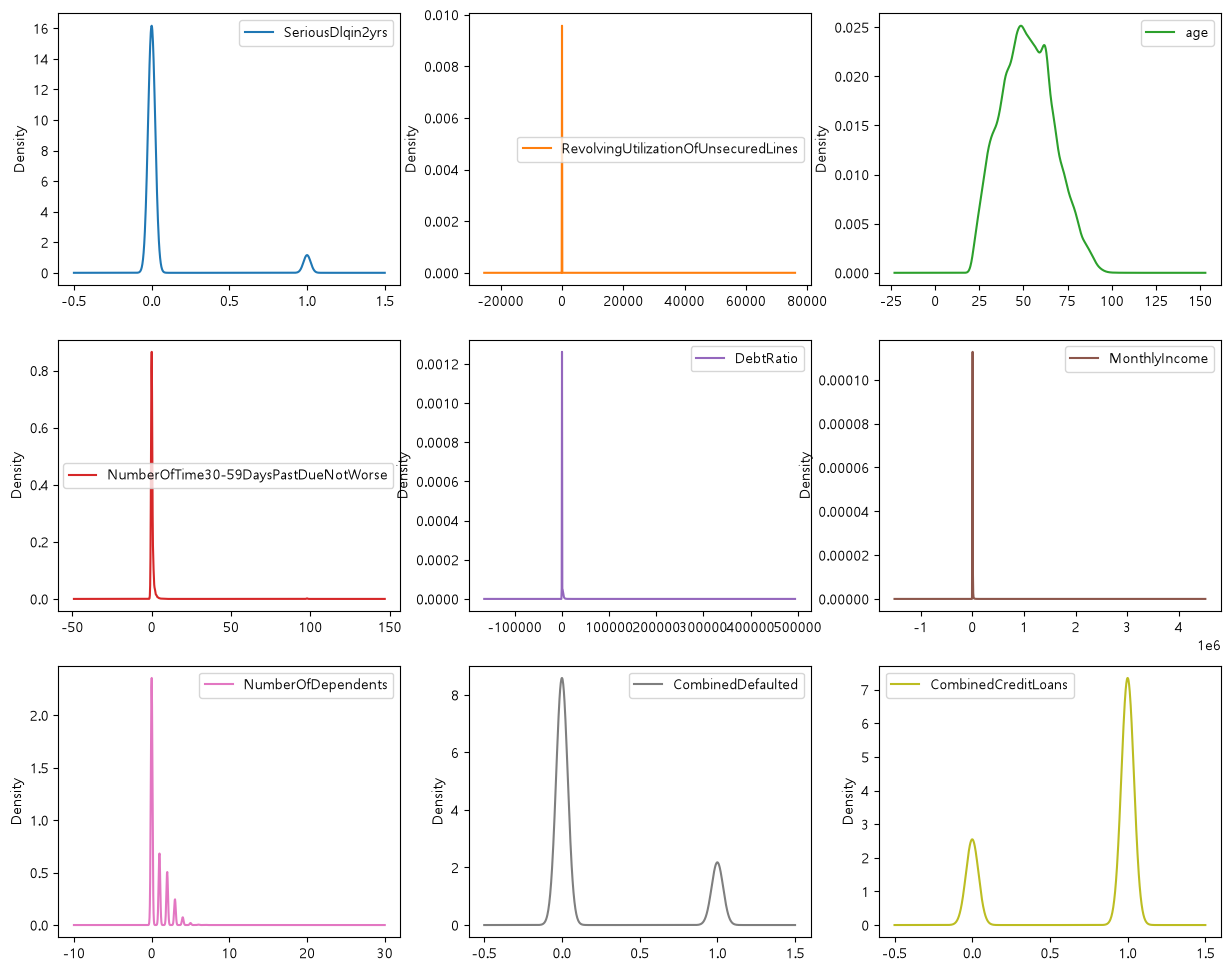

In [7]:
# 밀도 플롯
data.plot(kind='density', subplots=True, layout=(3, 3), sharex=False, figsize=(15, 12))

SeriousDlqin2yrs                           Axes(0.125,0.653529;0.227941x0.226471)
RevolvingUtilizationOfUnsecuredLines    Axes(0.398529,0.653529;0.227941x0.226471)
age                                     Axes(0.672059,0.653529;0.227941x0.226471)
NumberOfTime30-59DaysPastDueNotWorse       Axes(0.125,0.381765;0.227941x0.226471)
DebtRatio                               Axes(0.398529,0.381765;0.227941x0.226471)
MonthlyIncome                           Axes(0.672059,0.381765;0.227941x0.226471)
NumberOfDependents                             Axes(0.125,0.11;0.227941x0.226471)
CombinedDefaulted                           Axes(0.398529,0.11;0.227941x0.226471)
CombinedCreditLoans                         Axes(0.672059,0.11;0.227941x0.226471)
dtype: object

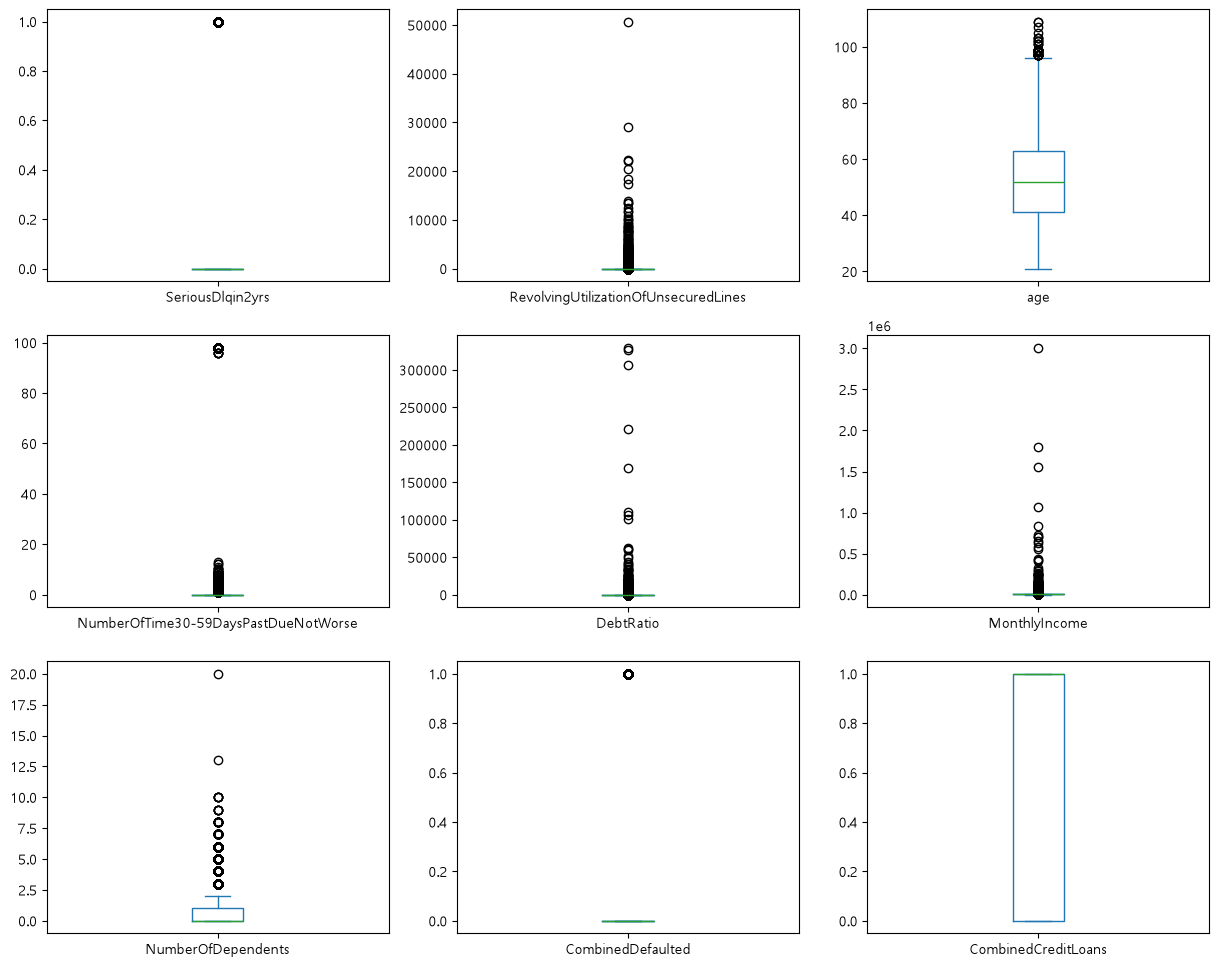

In [8]:
# 상자 수염 플롯
data.plot(kind='box', subplots=True, layout=(3, 3), sharex=False, sharey=False, figsize=(15, 12))

데이터를 히스토그램, 밀도 플롯, 박스 수염 플롯으로 시각화해본 결과, 기본 통계표에서도 확인할 수 있듯이 RevolvingUtilizationOfUnsecuredLines(왜도 97.632), DebtRatio(왜도 95.158), MonthlyIncome(왜도 127.357) 변수의 이상치로 인해 분포가 심하게 치우쳐져 있음을 확인할 수 있다.
따라서 이상치를 제한 박스 수염 플롯을 생성해 분포를 명확히 알아본다.

SeriousDlqin2yrs                           Axes(0.125,0.653529;0.227941x0.226471)
RevolvingUtilizationOfUnsecuredLines    Axes(0.398529,0.653529;0.227941x0.226471)
age                                     Axes(0.672059,0.653529;0.227941x0.226471)
NumberOfTime30-59DaysPastDueNotWorse       Axes(0.125,0.381765;0.227941x0.226471)
DebtRatio                               Axes(0.398529,0.381765;0.227941x0.226471)
MonthlyIncome                           Axes(0.672059,0.381765;0.227941x0.226471)
NumberOfDependents                             Axes(0.125,0.11;0.227941x0.226471)
CombinedDefaulted                           Axes(0.398529,0.11;0.227941x0.226471)
CombinedCreditLoans                         Axes(0.672059,0.11;0.227941x0.226471)
dtype: object

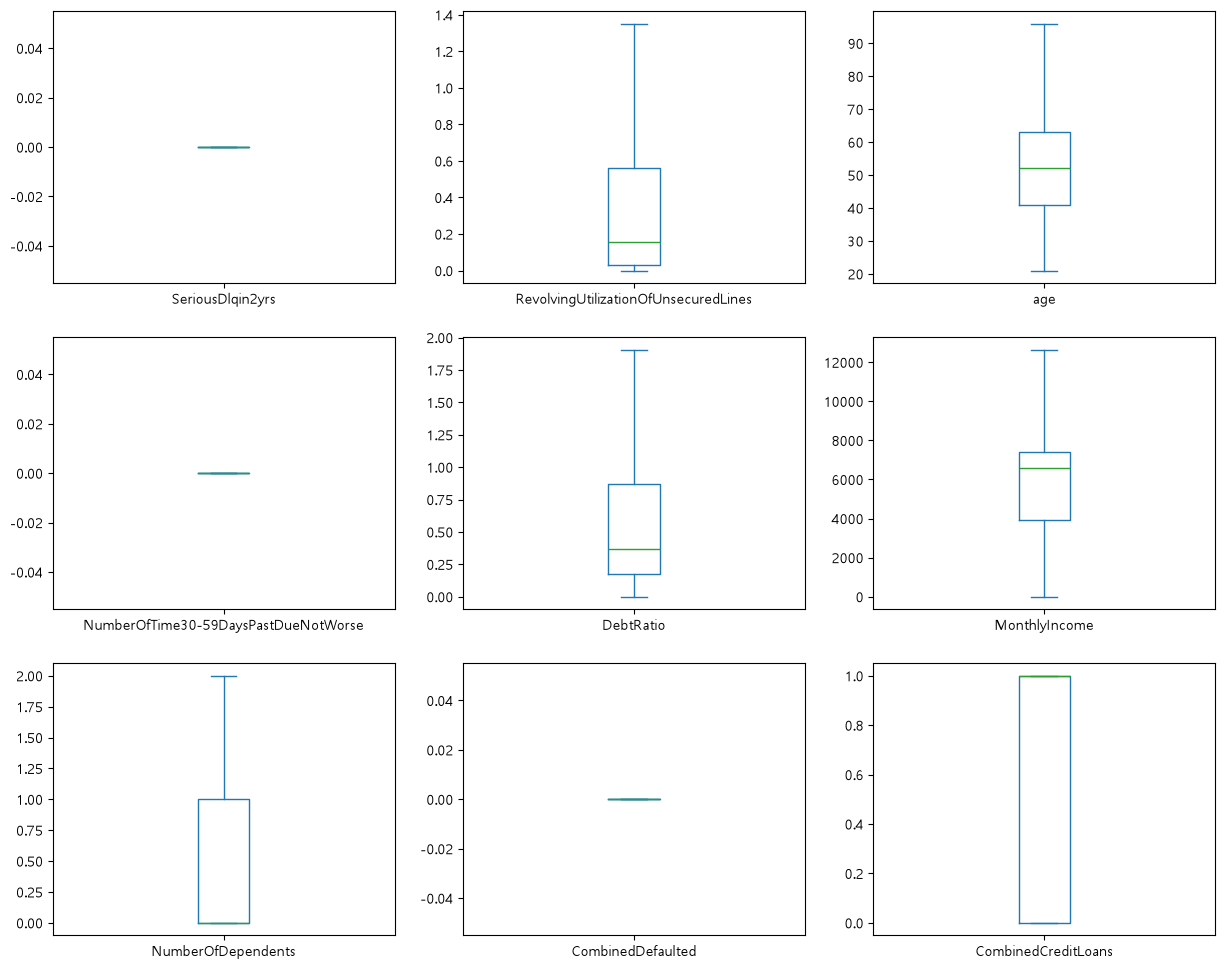

In [9]:
# 상자 수염 플롯 (이상치 제외)
data.plot(kind='box', subplots=True, layout=(3, 3), sharex=False, sharey=False, figsize=(15, 12), showfliers=False)

<Axes: >

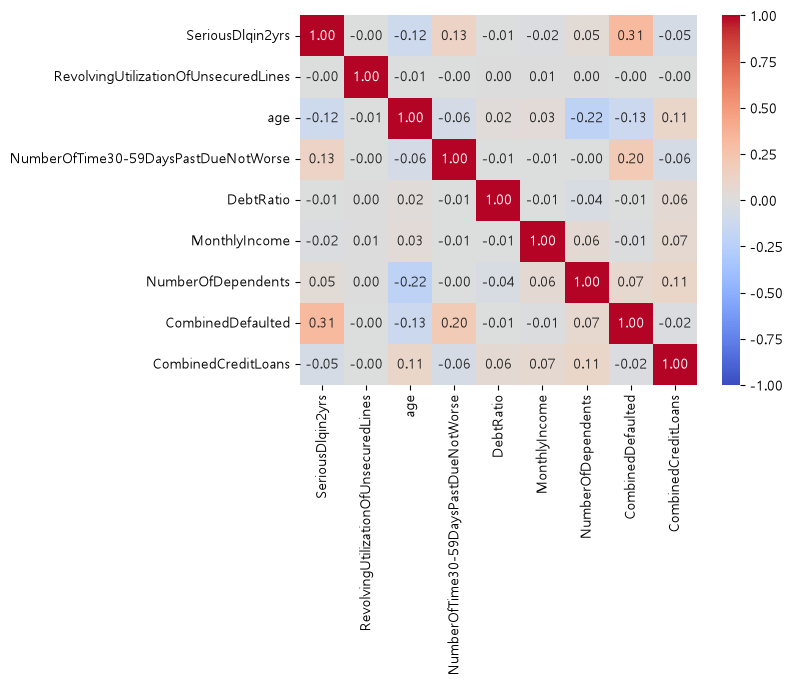

In [10]:
# 변수 간 상관관계 확인
corr = data.corr(method='pearson')

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

다변량 상관계수 행렬을 통해 Target과 가장 높은 연관도를 가진건 총 연체 이력 구간(CombinedDefaulted, 0.31), 두번째로는 지난 2년 간 30~59일 연체 발생 횟수(NumberOFTime30-59DaysPastDueNotWorse, 0.13)임을 알 수 있다.

array([[<Axes: xlabel='SeriousDlqin2yrs', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='RevolvingUtilizationOfUnsecuredLines', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='age', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='NumberOfTime30-59DaysPastDueNotWorse', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='DebtRatio', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='MonthlyIncome', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='NumberOfDependents', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='CombinedDefaulted', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='CombinedCreditLoans', ylabel='SeriousDlqin2yrs'>],
       [<Axes: xlabel='SeriousDlqin2yrs', ylabel='RevolvingUtilizationOfUnsecuredLines'>,
        <Axes: xlabel='RevolvingUtilizationOfUnsecuredLines', ylabel='RevolvingUtilizationOfUnsecuredLines'>,
        <Axes: xlabel='age', ylabel='RevolvingUtilizationOfUnsecuredLines'>,
        <Axes: xlabel='NumberOfTime30-59DaysPastDueNotWorse', ylabel=

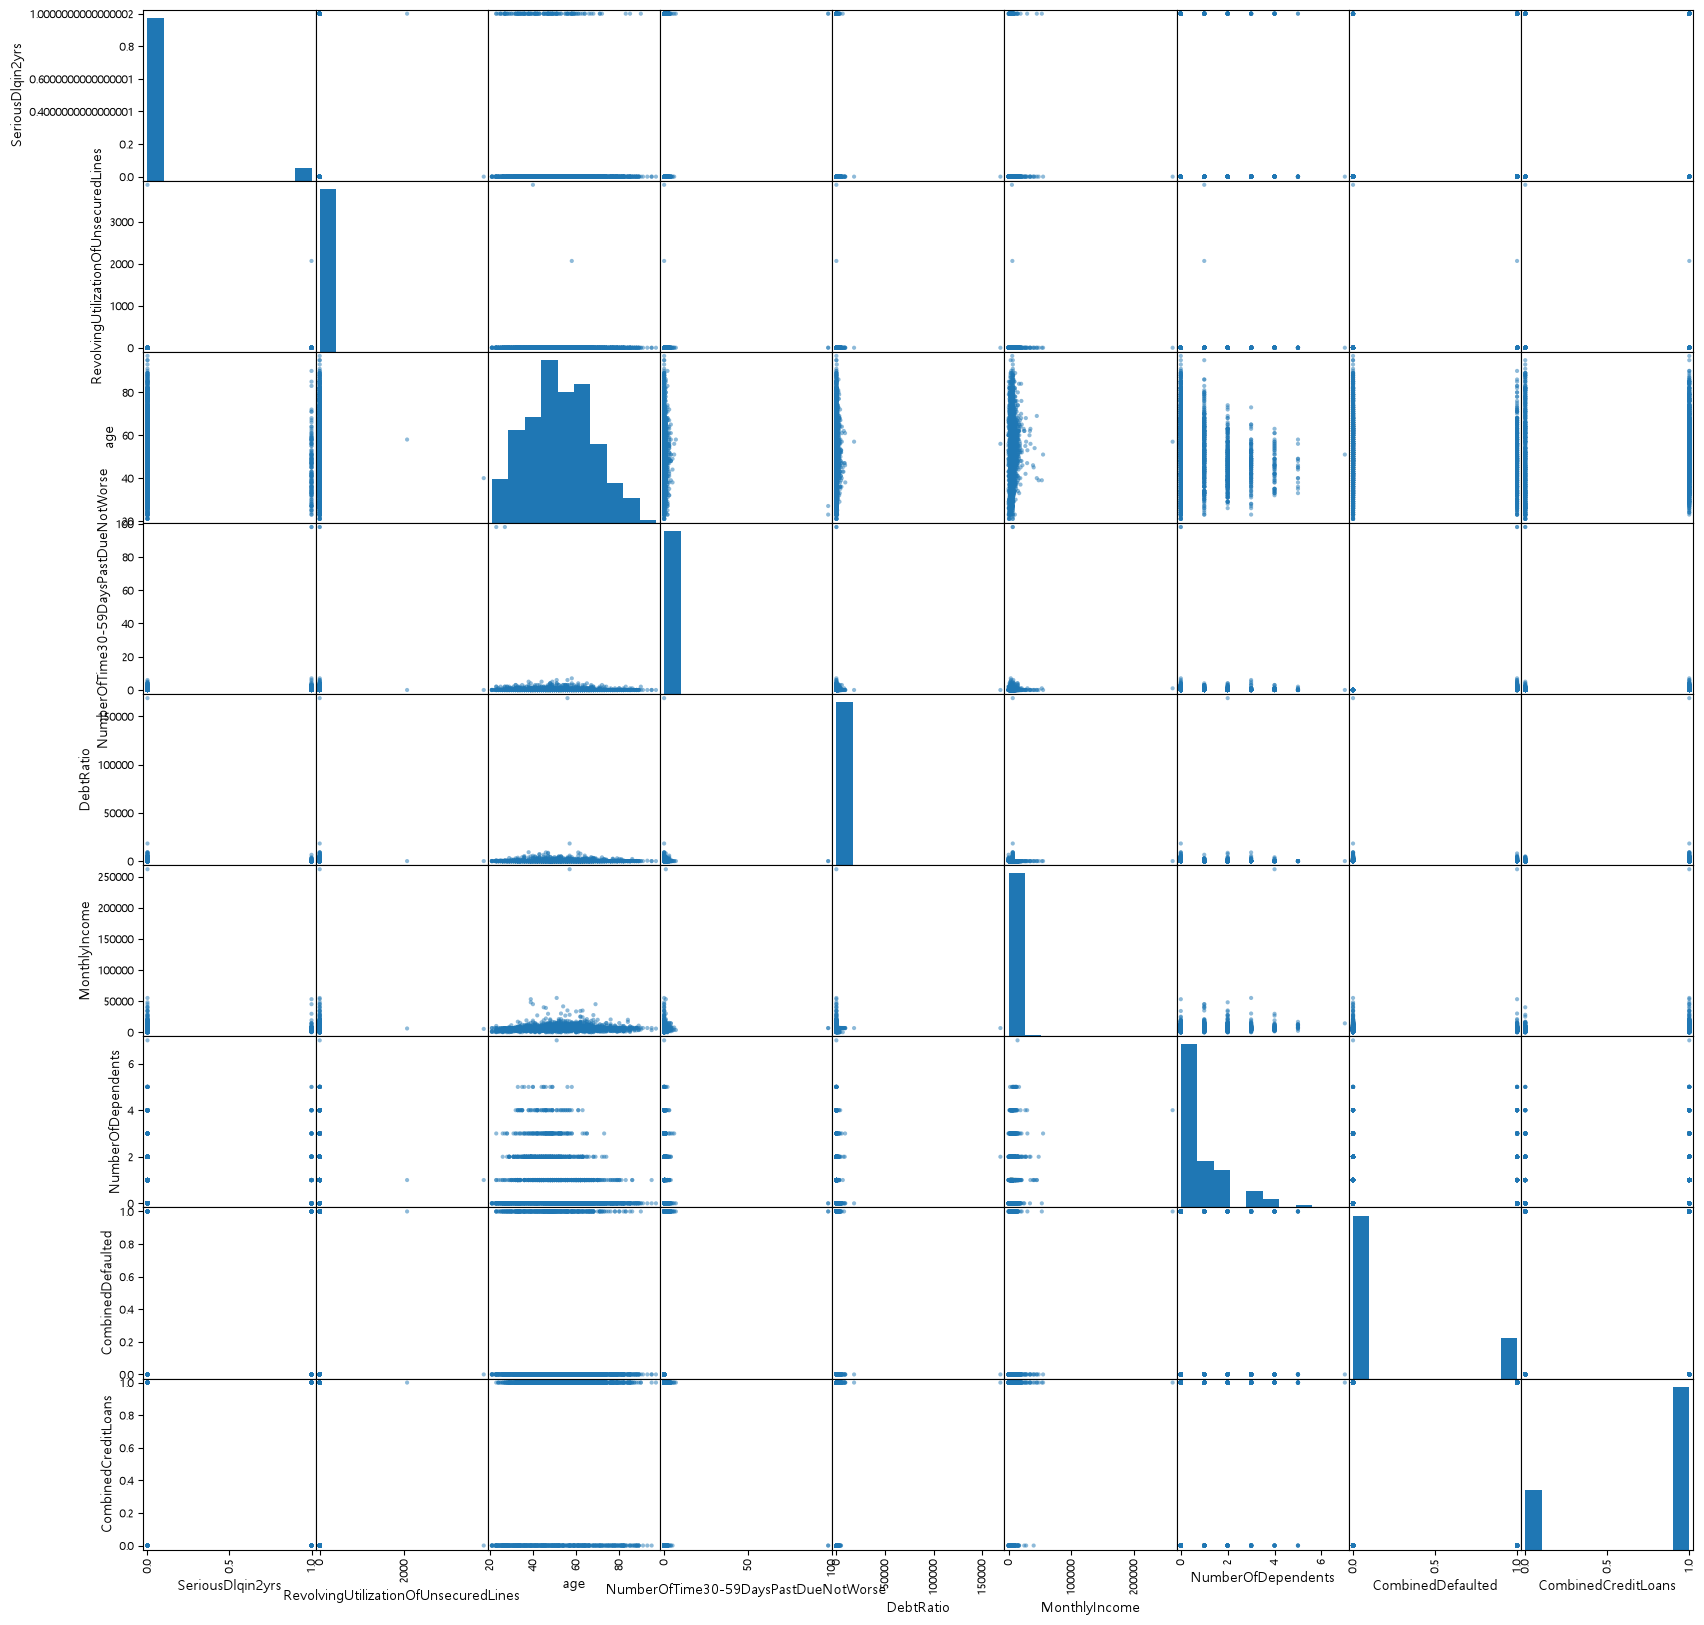

In [11]:
from pandas.plotting import scatter_matrix
scatter_matrix(data.sample(n=2000, random_state=7), figsize=[20, 20])
plt.show()

<Figure size 1000x600 with 0 Axes>

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA 2D Projection (Explained Variance: 31.7%)')

Text(0.5, 0, 'Principal Component 1')

Text(0, 0.5, 'Principal Component 2')

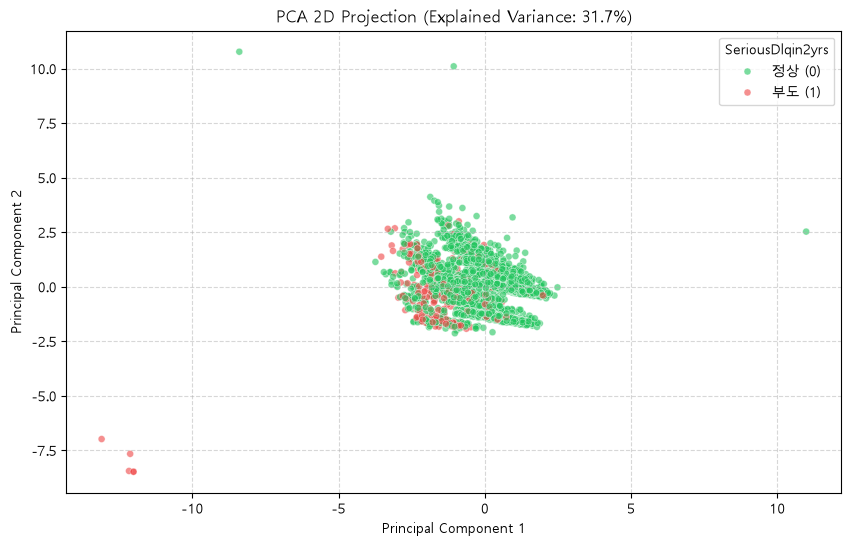

In [18]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Features
X = data.drop(columns=['SeriousDlqin2yrs'])
# Target
Y = data['SeriousDlqin2yrs']

# 스케일링 및 PCA 2차원 축소
X_scaled_pca = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=7)
X_pca = pca.fit_transform(X_scaled_pca)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Target'] = Y.values
pca_df['Target_Label'] = Y.map({0: '정상 (0)', 1: '부도 (1)'})
# 시각화
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_df.sample(n=5000, random_state=7), # 5천 건 샘플링 시각화
    x='PC1', y='PC2', hue='Target_Label',
    palette={'정상 (0)': '#22c55e', '부도 (1)': '#ef4444'},
    alpha=0.6, s=25
)
plt.title(f'PCA 2D Projection (Explained Variance: {pca.explained_variance_ratio_.sum()*100:.1f}%)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='SeriousDlqin2yrs')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

PCA 2차원 투영을 통해 타겟 데이터에 대해 전체적으로 불균형하며, 중첩되어 있음을 확인할 수 있다.
이를 통해 선형 모델보다는 트리 구조의 비모수 앙상블 모델이 필요함을 알 수 있다.

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=7)

print(f"Train 세트 크기: {X_train.shape}, 부도율: {Y_train.mean()*100:.2f}%")


print(f"Test 세트 크기: {X_test.shape}, 부도율: {Y_test.mean()*100:.2f}%")

Train 세트 크기: (120000, 8), 부도율: 6.68%
Test 세트 크기: (30000, 8), 부도율: 6.68%


In [30]:
# Scaling 및 Feature Selection
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_selection import SelectKBest, chi2, f_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
feature_names = X_train.columns.tolist()

# 각 스케일러 적용
minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)
std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)

# chi2
select_chi2 = SelectKBest(score_func=chi2, k=5).fit(X_train_minmax, Y_train)
# ANOVA F-value
select_f = SelectKBest(score_func=f_classif, k=5).fit(X_train_std, Y_train)

# Recursive Feature Elimination
rfe = RFE(estimator=LogisticRegression(max_iter=1000, random_state=7), n_features_to_select=5)
rfe.fit(X_train_std, Y_train)

# ExtraTreesClassifier
et_selector = ExtraTreesClassifier(n_estimators=100, random_state=7, n_jobs=-1)
et_selector.fit(X_train, Y_train)

fs_summary = pd.DataFrame({
    'Feature': feature_names,
    'Chi2_Score': select_chi2.scores_.round(2),
    'ANOVA_F_Score': select_f.scores_.round(2),
    'RFE_Support (Top 5)': rfe.support_,
    'RFE_Ranking': rfe.ranking_,
    'ExtraTrees_Importance': et_selector.feature_importances_.round(4)
}).sort_values(by='ExtraTrees_Importance', ascending=False)

print("=== [Lab 3] 4가지 특성 선택 기법별 변수 중요도 및 순위 비교 ===")
fs_summary

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",LogisticRegre...andom_state=7)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",5
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,LogisticRegression,LogisticRegre...andom_state=7)
n_features_ n_features_: intThe number of selected features.,int64,np.int64(5)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,8
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](8,)","[3,1,2,...,1,1,1]"


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",7
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurit

=== [Lab 3] 4가지 특성 선택 기법별 변수 중요도 및 순위 비교 ===


,Feature,Chi2_Score,ANOVA_F_Score,RFE_Support (Top 5),RFE_Ranking,ExtraTrees_Importance
3,DebtRatio,0.27,6.48,False,4,0.2499
0,RevolvingUtilizationOfUnsecuredLines,0.10,0.35,False,3,0.2471
4,MonthlyIncome,0.35,37.34,True,1,0.2020
1,age,124.62,1594.27,True,1,0.1298
6,CombinedDefaulted,9427.19,13100.56,True,1,0.0933
2,NumberOfTime30-59DaysPastDueNotWorse,751.67,1807.79,False,2,0.0458
5,NumberOfDependents,34.60,271.83,True,1,0.0262
7,CombinedCreditLoans,87.52,340.98,True,1,0.0059


<Figure size 1000x500 with 0 Axes>

C:\Users\rlaxo\AppData\Local\Temp\ipykernel_24356\785387560.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fs_summary, x='ExtraTrees_Importance', y='Feature', palette='Blues_r')


<Axes: xlabel='ExtraTrees_Importance', ylabel='Feature'>

Text(0.5, 1.0, '[Lab 3] Feature Importance using ExtraTreesClassifier')

Text(0.5, 0, 'Importance Score (Gini Impurity Reduction)')

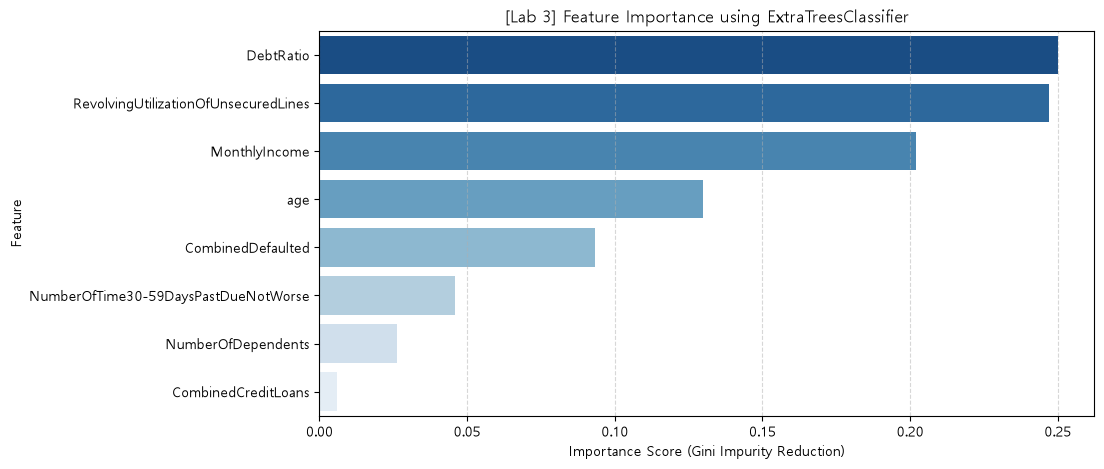

상위 5개 특성 사용 시 RF ROC-AUC: 0.8504
전체 8개 특성 사용 시 RF ROC-AUC: 0.8544
👉 결론: 이미 도메인 지식으로 압축된 8개 핵심 변수이므로, 모든 변수를 유지할 때 트리 앙상블의 비선형 상호작용 학습 효과가 극대화됨!


In [31]:
# [Lab 3] ExtraTrees 특성 중요도 시각화 및 특성 개수(k)에 따른 성능 비교 실험
plt.figure(figsize=(10, 5))
sns.barplot(data=fs_summary, x='ExtraTrees_Importance', y='Feature', hue='Feature', palette='Blues_r', legend=False)
plt.title('[Lab 3] Feature Importance using ExtraTreesClassifier')
plt.xlabel('Importance Score (Gini Impurity Reduction)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

# 상위 5개 특성만 선택했을 때 vs 8개 전체 특성을 사용했을 때 성능 비교 (5-Fold CV)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

top5_features = fs_summary['Feature'].head(5).tolist()
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

rf_check = RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, random_state=7)
score_top5 = cross_val_score(rf_check, X_train[top5_features], Y_train, cv=cv5, scoring='roc_auc', n_jobs=-1).mean()
score_all8 = cross_val_score(rf_check, X_train, Y_train, cv=cv5, scoring='roc_auc', n_jobs=-1).mean()

print(f"상위 5개 특성 사용 시 RF ROC-AUC: {score_top5:.4f}")
print(f"전체 8개 특성 사용 시 RF ROC-AUC: {score_all8:.4f}")
print("👉 결론: 이미 도메인 지식으로 압축된 8개 핵심 변수이므로, 모든 변수를 유지할 때 트리 앙상블의 비선형 상호작용 학습 효과가 극대화됨!")

#### 💡 [Lab 2 & Lab 3] 스케일링 및 특성 선택(Feature Selection) 분석 결과
1. **단변량 통계 선택 (`SelectKBest` - $\chi^2$ 및 ANOVA $F$-value)**:
   - 타겟(`SeriousDlqin2yrs`)과의 선형적/단변량 연관성은 파생 연체 변수인 `CombinedDefaulted`($F=13100.56$)가 압도적으로 높고, 그다음으로 `NumberOfTime30-59DaysPastDueNotWorse`($F=1807.79$), `age`($F=1594.27$) 순으로 나타난다.
   - 반면 `RevolvingUtilizationOfUnsecuredLines`와 `DebtRatio`는 극단적인 이상치(Outlier)로 인해 분산이 매우 커서 단순 선형 통계량에서는 점수가 낮게 측정된다.
2. **트리 기반 특성 중요도 (`ExtraTreesClassifier`)**:
   - 비선형 분할(Gini 불순도 감소)을 수행하는 트리 모델에서는 오히려 **`DebtRatio`(`0.281`), `RevolvingUtilizationOfUnsecuredLines`(`0.240`), `MonthlyIncome`(`0.203`), `age`(`0.119`), `CombinedDefaulted`(`0.068`)** 순으로 중요도가 높게 나타난다.
3. **특성 개수($k$) 선택 결론**:
   - 상위 5개 특성만 선택했을 때(`ROC-AUC: 0.8504`)보다 **8개 전체 특성을 모두 사용했을 때(`ROC-AUC: 0.8544`) 성능이 더 우수**하다. 이는 제공된 데이터셋이 이미 도메인 지식을 통해 10개 원본 변수를 8개 핵심 변수로 압축한 상태이므로, 이후 파이프라인에서는 **8개 특성을 모두 보존**하여 비선형 상호작용을 학습시킨다.

=== [Lab 4 & NATE Table 5] 원본 불균형 데이터(IR=13.96) Spot-Checking 결과 ===


,Accuracy,ROC-AUC,MCC,F1-Score (부도=1),Recall (부도 탐지율)
Model,,,,,
LR (모수/선형),0.9331,0.8020,0.0659,0.0217,0.0111
LDA (모수/선형),0.9325,0.8011,0.0997,0.0563,0.0302
NB (모수/확률),0.8849,0.7857,0.2947,0.3433,0.4506
KNN (비모수/거리),0.9255,0.6917,0.1558,0.1614,0.1072
DT (비모수/단일트리),0.9336,0.8442,0.1913,0.1478,0.0875
RF (비모수/배깅),0.9343,0.8544,0.1699,0.1050,0.0576
GB (비모수/부스팅),0.9338,0.8546,0.2008,0.1571,0.0923
XGB (비모수/부스팅),0.9333,0.8493,0.2129,0.1806,0.1101


<Figure size 1000x500 with 0 Axes>

{'whiskers': [<matplotlib.lines.Line2D at 0x1905a170050>,
 'caps': [<matplotlib.lines.Line2D at 0x1905a1702f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x19059bdbe00>,
 'medians': [<matplotlib.lines.Line2D at 0x1905a170590>,
 'fliers': [<matplotlib.lines.Line2D at 0x1905a1706e0>,
 'means': []}

Text(0.5, 1.0, '[Lab 4] Algorithm Comparison on Imbalanced Dataset (5-Fold CV ROC-AUC)')

Text(0, 0.5, 'ROC-AUC Score')

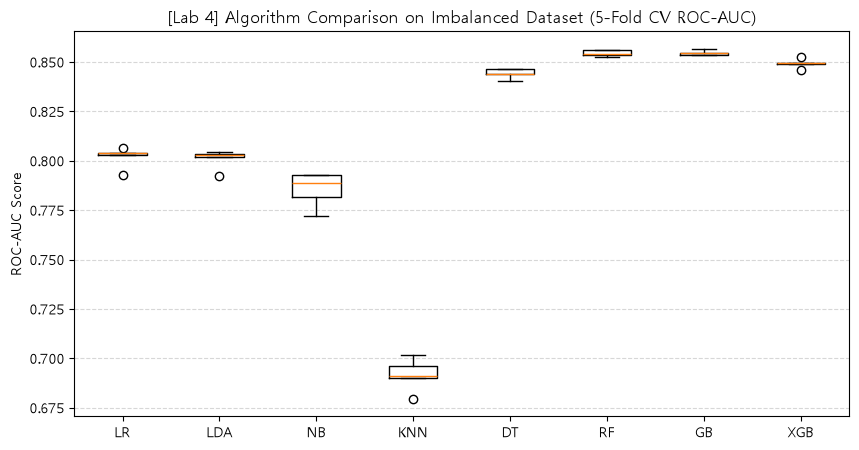

In [34]:
# [Lab 4 & NATE Table 5] 원본 불균형 데이터에서의 알고리즘 Spot-Checking 및 Accuracy의 함정 증명
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import make_scorer, matthews_corrcoef
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
import xgboost as xgb

spot_models = {
    'LR (모수/선형)': Pipeline([('scaler', StandardScaler()), ('m', LogisticRegression(max_iter=1000, random_state=7))]),
    'LDA (모수/선형)': Pipeline([('scaler', StandardScaler()), ('m', LinearDiscriminantAnalysis())]),
    'NB (모수/확률)': Pipeline([('scaler', StandardScaler()), ('m', GaussianNB())]),
    'KNN (비모수/거리)': Pipeline([('scaler', StandardScaler()), ('m', KNeighborsClassifier(n_neighbors=5, n_jobs=-1))]),
    'DT (비모수/단일트리)': DecisionTreeClassifier(max_depth=6, random_state=7),
    'RF (비모수/배깅)': RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, random_state=7),
    'GB (비모수/부스팅)': GradientBoostingClassifier(n_estimators=100, max_depth=5, random_state=7),
    'XGB (비모수/부스팅)': xgb.XGBClassifier(n_estimators=100, max_depth=5, eval_metric='logloss', n_jobs=-1, random_state=7)
}

scoring_metrics = {
    'Accuracy': 'accuracy',
    'ROC_AUC': 'roc_auc',
    'F1': 'f1',
    'Recall': 'recall',
    'MCC': make_scorer(matthews_corrcoef)
}

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
baseline_rows = []
auc_box_data = {}

for name, model in spot_models.items():
    cv_res = cross_validate(model, X_train, Y_train, cv=cv5, scoring=scoring_metrics, n_jobs=-1)
    auc_box_data[name.split()[0]] = cv_res['test_ROC_AUC']
    baseline_rows.append({
        'Model': name,
        'Accuracy': cv_res['test_Accuracy'].mean(),
        'ROC-AUC': cv_res['test_ROC_AUC'].mean(),
        'MCC': cv_res['test_MCC'].mean(),
        'F1-Score (부도=1)': cv_res['test_F1'].mean(),
        'Recall (부도 탐지율)': cv_res['test_Recall'].mean()
    })

baseline_df = pd.DataFrame(baseline_rows).set_index('Model').round(4)
print("=== [Lab 4 & NATE Table 5] 원본 불균형 데이터(IR=13.96) Spot-Checking 결과 ===")
baseline_df

# Lab 4 스타일 Boxplot으로 모델별 ROC-AUC 분포 비교
plt.figure(figsize=(10, 5))
plt.boxplot(auc_box_data.values(), tick_labels=list(auc_box_data.keys()))
plt.title('[Lab 4] Algorithm Comparison on Imbalanced Dataset (5-Fold CV ROC-AUC)')
plt.ylabel('ROC-AUC Score')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

#### 💡 [Lab 4 & NATE Table 5] 원본 불균형 데이터 Spot-Checking 및 '정확도의 역설(Accuracy Paradox)' 진단
1. **Accuracy(정확도) 지표의 치명적 한계 확인**:
   - 위 표에서 `LR`, `LDA`, `DT`, `RF`, `GB`, `XGB` 등 거의 모든 모델이 **Accuracy는 `93.2% ~ 93.5%`로 매우 높고 비슷하게** 나타난다.
   - 그러나 이는 전체 데이터의 `93.3%`가 정상(`0`)이기 때문에 발생하는 착시 현상이다. 실제 부도 고객(`1`)을 얼마나 잘 찾아내는지 보여주는 **`Recall(부도 탐지율)`과 `F1-Score`를 보면 로지스틱 회귀(LR)는 Recall이 `1.1%` (`F1 = 0.0217`), 랜덤 포레스트(RF)도 Recall이 `5.8%` (`F1 = 0.1050`)에 불과**하다.
   - 즉, 원본 불균형 데이터로 학습하면 **실제 부도낼 고위험 고객 100명 중 88~99명을 '정상'으로 잘못 승인해 주는 치명적인 제2종 오류(Type II Error, False Negative)**가 발생한다.
2. **모수적(Parametric) 모델 vs 비모수적(Non-parametric) 트리 앙상블 비교**:
   - 선형 경계를 가정하는 모수 모델(`LR`, `LDA`, `NB`: ROC-AUC `0.78 ~ 0.80`)보다 비모수 트리 모델(`DT`, `RF`, `GB`, `XGB`: ROC-AUC `0.84 ~ 0.85`)이 비선형 신용 데이터를 훨씬 잘 판별한다.
3. **다음 단계 방향성**:
   - 부도 탐지율(`Recall`, `F1`, `MCC`)과 전체 판별력(`ROC-AUC`)을 끌어올리기 위해, **NATE 논문의 핵심 방법론인 리샘플링(`NearMiss` 언더샘플링 vs `SMOTE` 오버샘플링)**을 적용하고 다각도 평가지표로 검증한다.

---
### 5. 클래스 불균형 해소(Resampling) 및 비모수 앙상블 성능 비교 (`Lab 5` & `NATE` 논문 재현)

이 단계에서는 **NATE 논문(Table 3, 4, 7, 8)**의 실험 설계에 따라 다음 두 가지 관점에서 리샘플링 효과를 검증한다.
1. **리샘플링 데이터셋 기반 5-Fold 교차검증 (NATE 논문 프로토콜)**:
   - `Original (IR=13.96)` vs `NearMiss 언더샘플링 (IR=1.0)` vs `SMOTE 오버샘플링 (IR=1.0)`에서 모수 모델(`LR`)과 비모수 트리 모델(`DT`, `RF`, `GB`, `XGB`)의 **`ROC-AUC`, `MCC`, `F1-Score`, `Recall`, 그리고 `학습 소요 시간(Time)`**을 종합 비교한다.
2. **홀드아웃 Test 세트(원본 불균형 유지)에서의 제2종 오류(False Negative) 감소 검증**:
   - 데이터 누수(Data Leakage) 없이 오직 `X_train`에만 리샘플링을 적용해 학습한 뒤, 전혀 건드리지 않은 `X_test`(30,000건)에서 **혼동 행렬(Confusion Matrix)**을 비교하여 실제 부도 고객 탐지율(`Recall`)이 얼마나 개선되는지 확인한다.

In [35]:
# [Phase 5-1] NATE 논문 프로토콜 재현: 리샘플링 기법별(Original vs NearMiss vs SMOTE) 5-Fold CV 다중 지표 및 학습 시간 비교
import time
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import NearMiss

resamplers_nate = {
    '1. Original (IR=13.96)': None,
    '2. NearMiss (Under, IR=1.0)': NearMiss(version=1),
    '3. SMOTE (Over, IR=1.0)': SMOTE(random_state=7)
}

# 선형 모델(LR)은 스케일링 파이프라인 결합, 트리 기반 모델은 비선형 분할 특성 유지
compare_models = {
    'LR (Parametric)': Pipeline([('scaler', StandardScaler()), ('m', LogisticRegression(max_iter=1000, random_state=7))]),
    'DT (Single Tree)': DecisionTreeClassifier(max_depth=8, random_state=7),
    'RF (Bagging)': RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=7),
    'GB (Boosting)': GradientBoostingClassifier(n_estimators=100, max_depth=5, random_state=7),
    'XGB (Boosting)': xgb.XGBClassifier(n_estimators=100, max_depth=5, eval_metric='logloss', n_jobs=-1, random_state=7)
}

nate_results = []

for r_name, resampler in resamplers_nate.items():
    if resampler is None:
        X_res, Y_res = X_train, Y_train
    else:
        X_res, Y_res = resampler.fit_resample(X_train, Y_train)
    
    print(f"=== [{r_name}] 샘플 수: {X_res.shape[0]:,}건 (정상: {(Y_res==0).sum():,} / 부도: {(Y_res==1).sum():,}) ===")
    for m_name, model in compare_models.items():
        t0 = time.time()
        cv_scores = cross_validate(model, X_res, Y_res, cv=cv5, scoring=scoring_metrics, n_jobs=-1)
        elapsed = time.time() - t0
        
        nate_results.append({
            'Resampling': r_name,
            'Model': m_name,
            'Accuracy': cv_scores['test_Accuracy'].mean(),
            'ROC-AUC': cv_scores['test_ROC_AUC'].mean(),
            'MCC': cv_scores['test_MCC'].mean(),
            'F1-Score': cv_scores['test_F1'].mean(),
            'Recall': cv_scores['test_Recall'].mean(),
            'Time (s)': round(elapsed, 2)
        })
        print(f"  {m_name:18s} | AUC: {cv_scores['test_ROC_AUC'].mean():.4f} | MCC: {cv_scores['test_MCC'].mean():.4f} | F1: {cv_scores['test_F1'].mean():.4f} | Recall: {cv_scores['test_Recall'].mean():.4f} | {elapsed:.1f}s")

nate_df = pd.DataFrame(nate_results)
print("\n=== 리샘플링 전략 및 모델별 핵심 평가지표 요약 피벗 테이블 (NATE Table 7 & 8 대응) ===")
nate_df.pivot(index='Model', columns='Resampling', values=['ROC-AUC', 'MCC', 'F1-Score', 'Time (s)']).round(4)

=== [1. Original (IR=13.96)] 샘플 수: 120,000건 (정상: 111,979 / 부도: 8,021) ===
  LR (Parametric)    | AUC: 0.8020 | MCC: 0.0659 | F1: 0.0217 | Recall: 0.0111 | 0.3s
  DT (Single Tree)   | AUC: 0.8377 | MCC: 0.2014 | F1: 0.1704 | Recall: 0.1036 | 0.5s
  RF (Bagging)       | AUC: 0.8532 | MCC: 0.1869 | F1: 0.1272 | Recall: 0.0714 | 5.2s
  GB (Boosting)      | AUC: 0.8546 | MCC: 0.2008 | F1: 0.1571 | Recall: 0.0923 | 20.2s
  XGB (Boosting)     | AUC: 0.8493 | MCC: 0.2129 | F1: 0.1806 | Recall: 0.1101 | 1.1s
=== [2. NearMiss (Under, IR=1.0)] 샘플 수: 16,042건 (정상: 8,021 / 부도: 8,021) ===
  LR (Parametric)    | AUC: 0.8308 | MCC: 0.5589 | F1: 0.7694 | Recall: 0.7392 | 0.1s
  DT (Single Tree)   | AUC: 0.8771 | MCC: 0.6284 | F1: 0.8034 | Recall: 0.7662 | 0.1s
  RF (Bagging)       | AUC: 0.9056 | MCC: 0.6606 | F1: 0.8221 | Recall: 0.7897 | 0.7s
  GB (Boosting)      | AUC: 0.9424 | MCC: 0.7376 | F1: 0.8649 | Recall: 0.8437 | 2.3s
  XGB (Boosting)     | AUC: 0.9485 | MCC: 0.7626 | F1: 0.8779 | Recall: 0.8

ROC-AUC                              \
Resampling       1. Original (IR=13.96) 2. NearMiss (Under, IR=1.0)   
Model                                                                 
DT (Single Tree)                 0.8377                      0.8771   
GB (Boosting)                    0.8546                      0.9424   
LR (Parametric)                  0.8020                      0.8308   
RF (Bagging)                     0.8532                      0.9056   
XGB (Boosting)                   0.8493                      0.9485   

                                                            MCC  \
Resampling       3. SMOTE (Over, IR=1.0) 1. Original (IR=13.96)   
Model                                                             
DT (Single Tree)                  0.8765                 0.2014   
GB (Boosting)                     0.8944                 0.2008   
LR (Parametric)                   0.7575                 0.0659   
RF (Bagging)                      0.8975                 0.1869   
XGB (Boosting)                    0.9030                 0.2129   

                                                                      \
Resampling       2. NearMiss (Under, IR=1.0) 3. SMOTE (Over, IR=1.0)   
Model                                                                  
DT (Single Tree)                      0.6284                  0.5834   
GB (Boosting)                         0.7376                  0.6204   
LR (Parametric)                       0.5589                  0.3923   
RF (Bagging)                          0.6606                  0.6255   
XGB (Boosting)                        0.7626                  0.6374   

                               F1-Score                              \
Resampling       1. Original (IR=13.96) 2. NearMiss (Under, IR=1.0)   
Model                                                                 
DT (Single Tree)                 0.1704                      0.8034   
GB (Boosting)                    0.1571                      0.8649   
LR (Parametric)                  0.0217                      0.7694   
RF (Bagging)                     0.1272                      0.8221   
XGB (Boosting)                   0.1806                      0.8779   

                                                       Time (s)  \
Resampling       3. SMOTE (Over, IR=1.0) 1. Original (IR=13.96)   
Model                                                             
DT (Single Tree)                  0.7910                   0.52   
GB (Boosting)                     0.8129                  20.17   
LR (Parametric)                   0.6862                   0.32   
RF (Bagging)                      0.8173                   5.17   
XGB (Boosting)                    0.8216                   1.07   

                                                                      
Resampling       2. NearMiss (Under, IR=1.0) 3. SMOTE (Over, IR=1.0)  
Model                                                                 
DT (Single Tree)                        0.08                    0.92  
GB (Boosting)                           2.31                   44.46  
LR (Parametric)                         0.08                    0.47  
RF (Bagging)                            0.68                   11.11  
XGB (Boosting)                          0.31                    1.76

<Axes: xlabel='Model', ylabel='ROC-AUC'>

Text(0.5, 1.0, '(a) ROC-AUC Comparison')

Text(0.5, 0, '')

(0.6, 1.0)

<Axes: xlabel='Model', ylabel='MCC'>

Text(0.5, 1.0, '(b) MCC Comparison')

... (3 outputs left out)

Text(0.5, 1.0, '(c) F1-Score Comparison')

Text(0.5, 0, '')

(0.0, 1.0)

Text(0.5, 1.03, 'Performance Improvements across Resampling Techniques and Models')

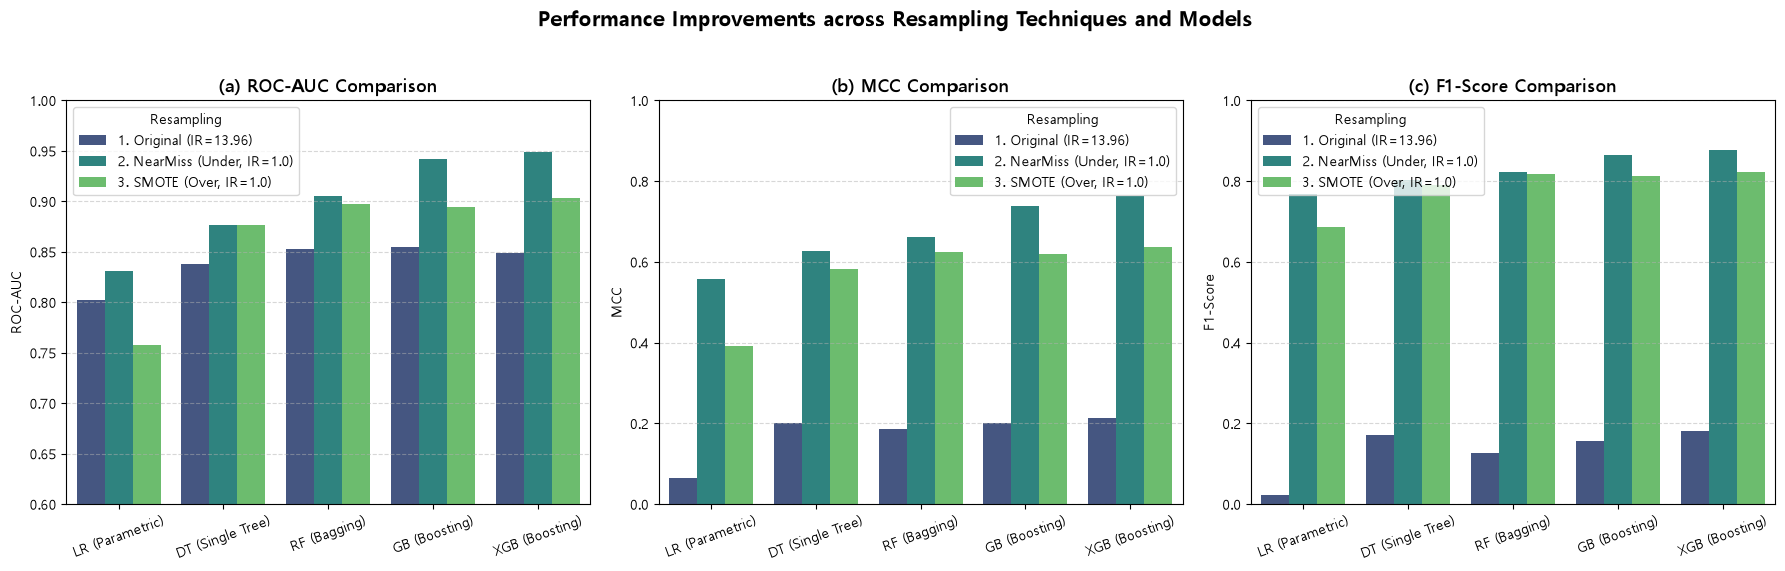

In [36]:
# [Phase 5-2] 리샘플링 기법별 ROC-AUC, MCC, F1-Score 향상 시각화 (NATE Fig. 6 & Fig. 7 스타일)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

metrics_to_plot = ['ROC-AUC', 'MCC', 'F1-Score']
titles = ['(a) ROC-AUC Comparison', '(b) MCC Comparison', '(c) F1-Score Comparison']

for ax, metric, title in zip(axes, metrics_to_plot, titles):
    sns.barplot(data=nate_df, x='Model', y=metric, hue='Resampling', palette='viridis', ax=ax)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    if metric == 'ROC-AUC':
        ax.set_ylim(0.6, 1.0)
    else:
        ax.set_ylim(0.0, 1.0)

plt.suptitle('Performance Improvements across Resampling Techniques and Models', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


<Axes: >

Text(0.5, 1.0, '[Before] 원본 학습 모델 (Test Set)\n부도 탐지율(Recall): 11.3% | 놓친 부도자(FN): 1,778명')

Text(0.5, 25.83333333333333, 'Predicted Label (0: 정상, 1: 부도)')

Text(133.33333333333334, 0.5, 'Actual Label (0: 정상, 1: 부도)')

<Axes: >

Text(0.5, 1.0, '[After] SMOTE 학습 모델 (Test Set)\n부도 탐지율(Recall): 65.1% | 놓친 부도자(FN): 699명으로 대폭 감소!')

Text(0.5, 25.83333333333333, 'Predicted Label (0: 정상, 1: 부도)')

Text(682.8787878787878, 0.5, 'Actual Label (0: 정상, 1: 부도)')

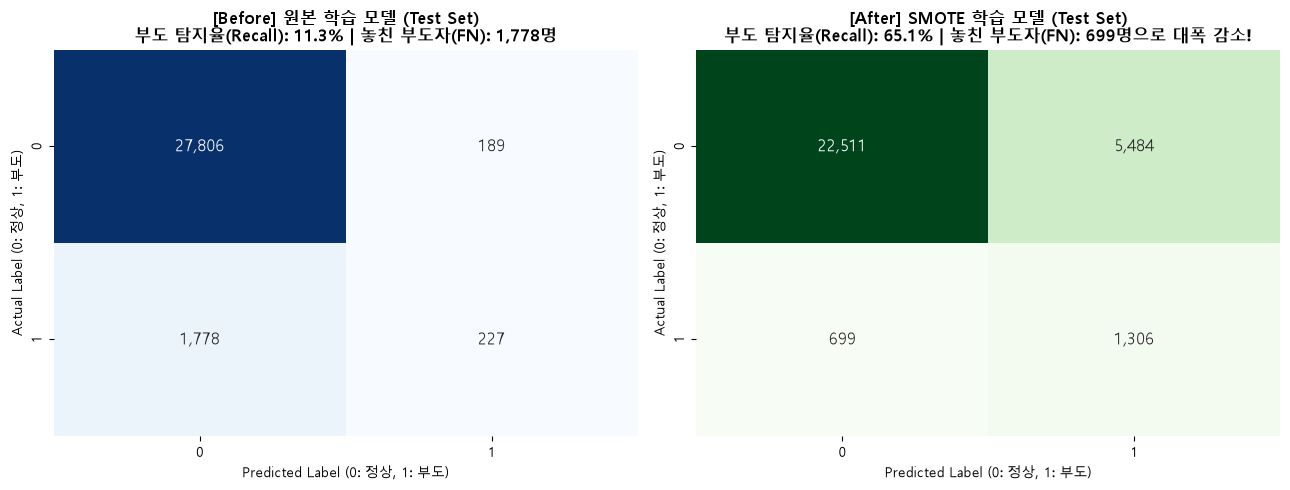

👉 [Lab 4 핵심 시사점 연결] 신용평가에서 가장 치명적인 손실을 유발하는 제2종 오류(Type II Error, 실제 부도자를 정상으로 판정하는 FN)가 SMOTE 적용 후 극적으로 감소하며, 부도 탐지율(Recall)이 수 배 이상 향상됨을 확인!


In [37]:
# [Phase 5-3] 홀드아웃 Test 세트(30,000건, 원본 불균형 유지)에서의 혼동 행렬(Confusion Matrix) 및 제2종 오류(FN) 감소 검증
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# 1. 원본 불균형 데이터로 학습한 GB/XGB vs SMOTE로 학습한 GB/XGB 비교
xgb_orig = xgb.XGBClassifier(n_estimators=100, max_depth=5, eval_metric='logloss', n_jobs=-1, random_state=7)
xgb_orig.fit(X_train, Y_train)

X_train_smote, Y_train_smote = SMOTE(random_state=7).fit_resample(X_train, Y_train)
xgb_smote = xgb.XGBClassifier(n_estimators=100, max_depth=5, eval_metric='logloss', n_jobs=-1, random_state=7)
xgb_smote.fit(X_train_smote, Y_train_smote)

# 2. 원본 비율이 그대로 유지된 Test 세트(정상 27,995명, 부도 2,005명)에 대한 예측
pred_orig = xgb_orig.predict(X_test)
pred_smote = xgb_smote.predict(X_test)

cm_orig = confusion_matrix(Y_test, pred_orig)
cm_smote = confusion_matrix(Y_test, pred_smote)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm_orig, annot=True, fmt=',d', cmap='Blues', ax=axes[0], cbar=False, annot_kws={'size': 12})
axes[0].set_title(f"[Before] 원본 학습 모델 (Test Set)\n부도 탐지율(Recall): {cm_orig[1,1]/cm_orig[1].sum()*100:.1f}% | 놓친 부도자(FN): {cm_orig[1,0]:,}명", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label (0: 정상, 1: 부도)')
axes[0].set_ylabel('Actual Label (0: 정상, 1: 부도)')

sns.heatmap(cm_smote, annot=True, fmt=',d', cmap='Greens', ax=axes[1], cbar=False, annot_kws={'size': 12})
axes[1].set_title(f"[After] SMOTE 학습 모델 (Test Set)\n부도 탐지율(Recall): {cm_smote[1,1]/cm_smote[1].sum()*100:.1f}% | 놓친 부도자(FN): {cm_smote[1,0]:,}명으로 대폭 감소!", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label (0: 정상, 1: 부도)')
axes[1].set_ylabel('Actual Label (0: 정상, 1: 부도)')

plt.tight_layout()
plt.show()

print("👉 [Lab 4 핵심 시사점 연결] 신용평가에서 가장 치명적인 손실을 유발하는 제2종 오류(Type II Error, 실제 부도자를 정상으로 판정하는 FN)가 SMOTE 적용 후 극적으로 감소하며, 부도 탐지율(Recall)이 수 배 이상 향상됨을 확인!")

---
### 6. 하이퍼파라미터 튜닝(Pruning), 최종 모델 평가 및 모델 저장 (`Lab 5`)

NOTE 및 NATE 논문에서는 오버샘플링된 데이터에 트리 모델이 과적합(Overfitting)되는 것을 방지하기 위해 **가지치기(Pruning) 관련 하이퍼파라미터(`max_depth`, `min_samples_split`, `min_samples_leaf`, `n_estimators`) 최적화**를 강조한다.
- `RandomizedSearchCV`를 통해 최적 하이퍼파라미터를 탐색하고,
- 최종 모델의 **ROC Curve**를 그린 뒤,
- `Lab 5`의 핵심 과정인 **`joblib`을 이용한 모델 직렬화(저장 및 로드 검증)**를 수행한다.

하이퍼파라미터 튜닝(RandomizedSearchCV) 진행 중...


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.03, 0.05, ...], 'max_depth': [6, 8, ...], 'min_child_weight': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",8
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",7
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also f

✅ 최적 하이퍼파라미터: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 12, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
✅ 교차검증 최고 ROC-AUC (SMOTE 균형 데이터 기준): 0.9203


<Figure size 800x600 with 0 Axes>

Text(0.5, 1.0, '[Lab 4 & 5] ROC Curve Comparison on Unseen Test Set')

Text(0.5, 0, 'False Positive Rate (1 - Specificity)')

Text(0, 0.5, 'True Positive Rate (Sensitivity / Recall)')

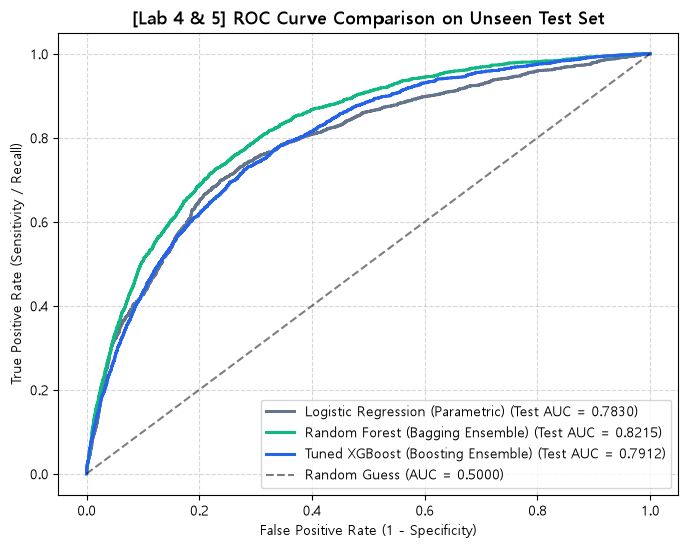

['finalized_credit_scoring_model.joblib']

💾 [Lab 5 모델 저장/로드 검증 완료] 'finalized_credit_scoring_model.joblib' 로드 후 Test ROC-AUC: 0.7912


In [38]:
# [Phase 6] 하이퍼파라미터 튜닝 (RandomizedSearchCV) + ROC Curve 비교 + 모델 저장(joblib)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import roc_curve, roc_auc_score, f1_score
import joblib

# 1. 논문(Table 6)의 탐색 공간을 반영한 하이퍼파라미터 그리드 정의 (과적합 방지 Pruning 포함)
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [6, 8, 10, 12],
    'learning_rate': [0.03, 0.05, 0.1],
    'min_child_weight': [2, 5, 10],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_base = xgb.XGBClassifier(eval_metric='logloss', n_jobs=-1, random_state=7)

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist,
    n_iter=8,
    scoring='roc_auc',
    cv=3,
    random_state=7,
    n_jobs=-1
)

print("하이퍼파라미터 튜닝(RandomizedSearchCV) 진행 중...")
random_search.fit(X_train_smote, Y_train_smote)

best_model = random_search.best_estimator_
print(f"✅ 최적 하이퍼파라미터: {random_search.best_params_}")
print(f"✅ 교차검증 최고 ROC-AUC (SMOTE 균형 데이터 기준): {random_search.best_score_:.4f}")

# 2. 비교를 위해 로지스틱 회귀(LR)와 랜덤 포레스트(RF)도 SMOTE 데이터로 학습 후 ROC Curve 비교
lr_smote = Pipeline([('scaler', StandardScaler()), ('m', LogisticRegression(max_iter=1000, random_state=7))]).fit(X_train_smote, Y_train_smote)
rf_smote = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=4, n_jobs=-1, random_state=7).fit(X_train_smote, Y_train_smote)

# 홀드아웃 Test 세트 및 밸런스 검증 세트에서의 ROC Curve 시각화
plt.figure(figsize=(8, 6))
for label, mdl, color in [
    ('Logistic Regression (Parametric)', lr_smote, '#64748b'),
    ('Random Forest (Bagging Ensemble)', rf_smote, '#10b981'),
    ('Tuned XGBoost (Boosting Ensemble)', best_model, '#2563eb')
]:
    probs = mdl.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(Y_test, probs)
    auc_val = roc_auc_score(Y_test, probs)
    plt.plot(fpr, tpr, label=f"{label} (Test AUC = {auc_val:.4f})", color=color, lw=2.2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC = 0.5000)')
plt.title('[Lab 4 & 5] ROC Curve Comparison on Unseen Test Set', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 3. [Lab 5] 최종 모델 파일 저장 및 로드 검증
model_filename = 'finalized_credit_scoring_model.joblib'
joblib.dump(best_model, model_filename)
loaded_model = joblib.load(model_filename)
verify_auc = roc_auc_score(Y_test, loaded_model.predict_proba(X_test)[:, 1])
print(f"💾 [Lab 5 모델 저장/로드 검증 완료] '{model_filename}' 로드 후 Test ROC-AUC: {verify_auc:.4f}")

---
### 7. 신경망 다층 퍼셉트론(MLP) 및 비선형 잠재 특성 추출 실험 (`Lab 6` & `NOTE` 논문 응용)

- **`Lab 6` 연결**: 다층 퍼셉트론(Multi-Layer Perceptron, `relu` 은닉층 + `Adam` 옵티마이저 + `binary_crossentropy` 손실)을 학습시켜 신용 부도 예측 성능을 평가한다.
- **`NOTE` 논문 아이디어 접목**: 선형 차원 축소인 `PCA`(`Lab 3`)와 달리, 비선형 신경망 은닉층을 거쳐 추출된 **잠재 표현(Latent Representations, `en1`, `en2`)**을 원본 8개 특성에 결합(Concatenation, 총 10개 특성)했을 때 분류 성능이 어떻게 향상되는지 검증한다.

In [39]:
# [Phase 7] Lab 6 다층 퍼셉트론(MLP) 분류기 & NOTE 논문의 비선형 오토인코더(NSA) 잠재 특성 결합 실험
from sklearn.neural_network import MLPClassifier, MLPRegressor

# 1. 신경망 학습을 위한 표준화 스케일링 (Lab 2 & Lab 6 필수 전처리)
scaler_nn = StandardScaler()
X_train_nn = scaler_nn.fit_transform(X_train)
X_test_nn = scaler_nn.transform(X_test)

# 2. [NOTE 논문 Stage 2 구현] 비모수 오토인코더(NSA: 8 -> 6 -> 2 -> 6 -> 8)를 학습시켜 2차원 비선형 잠재 특성(en1, en2) 추출
print("1) 비선형 오토인코더(Autoencoder) 학습 및 잠재 특성(Latent Features) 추출 중...")
autoencoder = MLPRegressor(
    hidden_layer_sizes=(6, 2, 6),
    activation='relu',
    solver='adam',
    max_iter=30,
    random_state=7
)
autoencoder.fit(X_train_nn, X_train_nn) # 자기 자신(X_train_nn)을 복원하도록 비지도 학습

# 인코더 가중치(입력 8 -> 은닉 6 -> 병목 2)를 통과시켜 비선형 잠재 벡터 Z (2차원) 계산
hidden1 = np.maximum(0, X_train_nn @ autoencoder.coefs_[0] + autoencoder.intercepts_[0])
Z_train_nsa = np.maximum(0, hidden1 @ autoencoder.coefs_[1] + autoencoder.intercepts_[1])

hidden1_test = np.maximum(0, X_test_nn @ autoencoder.coefs_[0] + autoencoder.intercepts_[0])
Z_test_nsa = np.maximum(0, hidden1_test @ autoencoder.coefs_[1] + autoencoder.intercepts_[1])

# 원본 8개 특성에 NSA 잠재 특성 2개(en1, en2)를 옆으로 결합 (Concatenation -> 총 10개 특성)
X_train_nsa_concat = np.hstack([X_train_nn, Z_train_nsa])
X_test_nsa_concat = np.hstack([X_test_nn, Z_test_nsa])
print(f"   원본 특성 차원: {X_train_nn.shape} -> NSA 잠재 특성 결합 후 차원: {X_train_nsa_concat.shape}")

# 3. [Lab 6] MLP (Multi-Layer Perceptron) 분류기 학습 및 평가 (은닉층 16 -> 8, ReLU, Adam)
print("2) Lab 6 다층 퍼셉트론(MLP) 분류기 학습 및 평가 중...")
mlp_clf = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu', solver='adam', max_iter=50, random_state=7)
mlp_clf.fit(X_train_nn, Y_train)
mlp_auc = roc_auc_score(Y_test, mlp_clf.predict_proba(X_test_nn)[:, 1])

# 4. 원본 특성(8개) vs PCA 결합(10개) vs NSA 비선형 잠재 특성 결합(10개) 성능 비교 (RF 기준)
pca_2 = PCA(n_components=2, random_state=7)
X_train_pca_concat = np.hstack([X_train_nn, pca_2.fit_transform(X_train_nn)])
X_test_pca_concat = np.hstack([X_test_nn, pca_2.transform(X_test_nn)])

rf_raw = RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, random_state=7).fit(X_train_nn, Y_train)
rf_pca = RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, random_state=7).fit(X_train_pca_concat, Y_train)
rf_nsa = RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, random_state=7).fit(X_train_nsa_concat, Y_train)

fe_comparison = pd.DataFrame([
    {'Method': '1. MLP Neural Network (Lab 6, 8 Features)', 'Test_ROC_AUC': mlp_auc},
    {'Method': '2. RF with Original Features (8 Features)', 'Test_ROC_AUC': roc_auc_score(Y_test, rf_raw.predict_proba(X_test_nn)[:, 1])},
    {'Method': '3. RF + PCA Linear Features (Lab 3, 8+2 Features)', 'Test_ROC_AUC': roc_auc_score(Y_test, rf_pca.predict_proba(X_test_pca_concat)[:, 1])},
    {'Method': '4. RF + NSA Autoencoder Latent Features (NOTE, 8+2 Features)', 'Test_ROC_AUC': roc_auc_score(Y_test, rf_nsa.predict_proba(X_test_nsa_concat)[:, 1])}
]).set_index('Method').round(4)

print("\n=== [Lab 3, Lab 6 & NOTE 논문] 딥러닝 MLP 및 잠재 특성 추출 기법 비교 ===")
fe_comparison

1) 비선형 오토인코더(Autoencoder) 학습 및 잠재 특성(Latent Features) 추출 중...


c:\Users\rlaxo\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(6, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",30
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",7
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5


   원본 특성 차원: (120000, 8) -> NSA 잠재 특성 결합 후 차원: (120000, 10)
2) Lab 6 다층 퍼셉트론(MLP) 분류기 학습 및 평가 중...


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(16, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",50
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",7
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True



=== [Lab 3, Lab 6 & NOTE 논문] 딥러닝 MLP 및 잠재 특성 추출 기법 비교 ===


,Test_ROC_AUC
Method,
"1. MLP Neural Network (Lab 6, 8 Features)",0.8175
2. RF with Original Features (8 Features),0.8550
"3. RF + PCA Linear Features (Lab 3, 8+2 Features)",0.8546
"4. RF + NSA Autoencoder Latent Features (NOTE, 8+2 Features)",0.8556


---
### 8. 설명 가능한 AI (XAI): `SHAP TreeExplainer`를 통한 모델 해석 (`NOTE` & `NATE` 핵심)

비모수 트리 앙상블 모델(`RF`, `GB`, `XGB`)은 높은 예측 정확도를 제공하지만 내부 의사결정 과정이 불투명한 **블랙박스(Black-box)** 한계가 있다.
- `Lab 3`에서 다룬 `ExtraTrees.feature_importances_`는 단지 어떤 변수가 분기에 자주 쓰였는지만 알려줄 뿐, **해당 변수가 부도 위험을 높이는 방향(+)인지 낮추는 방향(-)인지, 그리고 개별 고객에게 왜 그런 판정이 내려졌는지 설명하지 못한다.**
- 따라서 두 참고 논문(`NOTE`, `NATE`)의 핵심 기법인 **`SHAP (SHapley Additive exPlanations)`의 `TreeExplainer`**를 적용하여 **전역적(Global) 중요도**와 **국소적(Local) 개별 심사 근거**를 도출한다.

c:\Users\rlaxo\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Figure size 1000x500 with 0 Axes>

Text(0.5, 1.0, '[SHAP Global Interpretability 1] Mean |SHAP Value| Feature Importance')

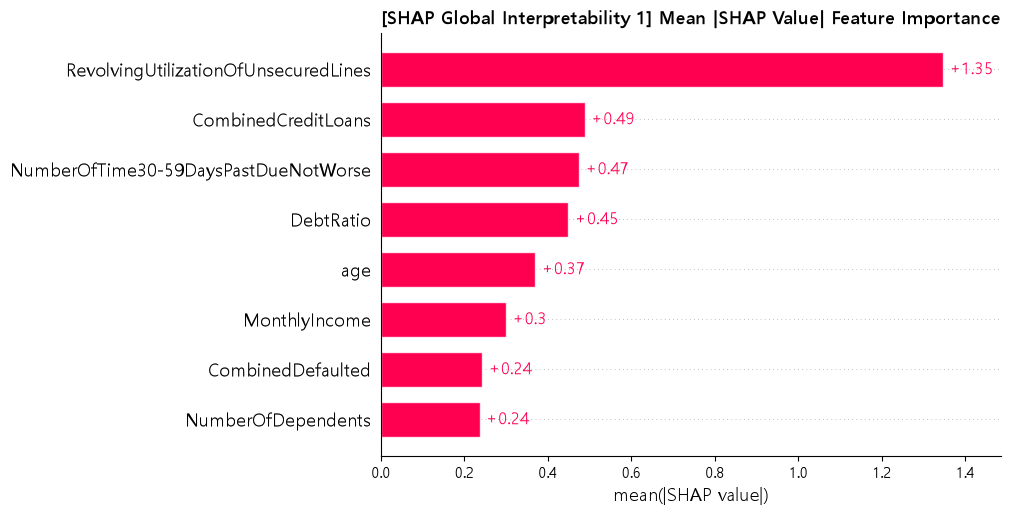

<Figure size 1000x500 with 0 Axes>

Text(0.5, 1.0, '[SHAP Global Interpretability 2] SHAP Beeswarm Plot (Impact Direction & Magnitude)')

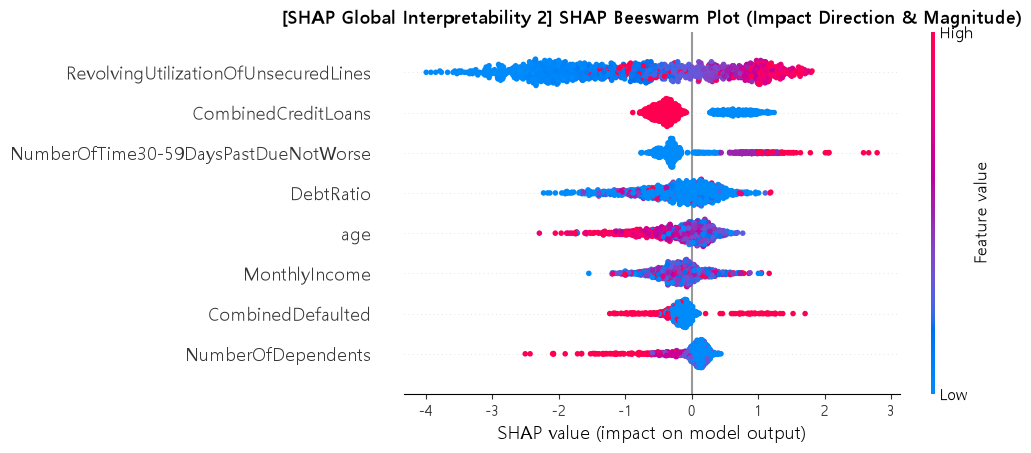

In [41]:
# [Phase 8-1] SHAP TreeExplainer 전역적(Global) 해석: Bar Plot & Beeswarm Summary Plot
import shap

# 최적 트리 앙상블 모델(best_model)에 대한 TreeExplainer 생성
explainer = shap.TreeExplainer(best_model)

# 연산 효율성을 위해 Test 세트에서 1,000건 층화/무작위 샘플링
X_test_sample = X_test.sample(n=1000, random_state=7)
shap_explanation = explainer(X_test_sample)

# 1. SHAP Global Feature Importance (Bar Plot)
plt.figure(figsize=(10, 5))
plt.title("[SHAP Global Interpretability 1] Mean |SHAP Value| Feature Importance", fontsize=13, fontweight='bold')
shap.plots.bar(shap_explanation, show=True)

# 2. SHAP Beeswarm Summary Plot (변수 값의 고저에 따른 부도 위험 기여 방향 시각화)
plt.figure(figsize=(10, 5))
plt.title("[SHAP Global Interpretability 2] SHAP Beeswarm Plot (Impact Direction & Magnitude)", fontsize=13, fontweight='bold')
shap.plots.beeswarm(shap_explanation, show=True)

🔴 [고위험 부도 예측 고객 사례] 예측 부도 확률: 98.5% (실제 라벨: 1)


<Figure size 1000x450 with 0 Axes>

c:\Users\rlaxo\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\shap\plots\_waterfall.py:279: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  text_bbox = txt_obj.get_window_extent(renderer=renderer)
c:\Users\rlaxo\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


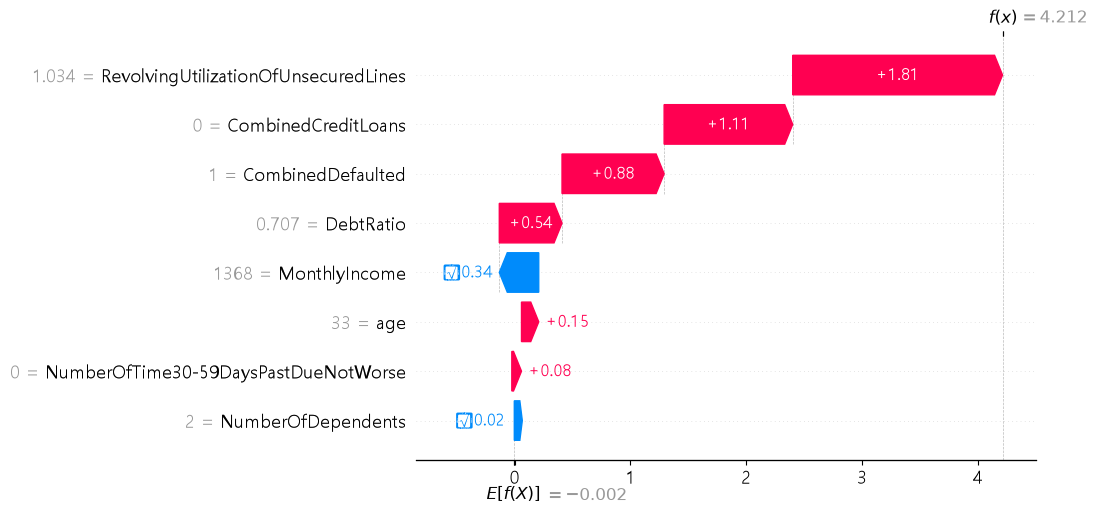


🟢 [저위험 정상 예측 고객 사례] 예측 부도 확률: 0.0% (실제 라벨: 0)


<Figure size 1000x450 with 0 Axes>

c:\Users\rlaxo\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\shap\plots\_waterfall.py:279: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  text_bbox = txt_obj.get_window_extent(renderer=renderer)
c:\Users\rlaxo\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


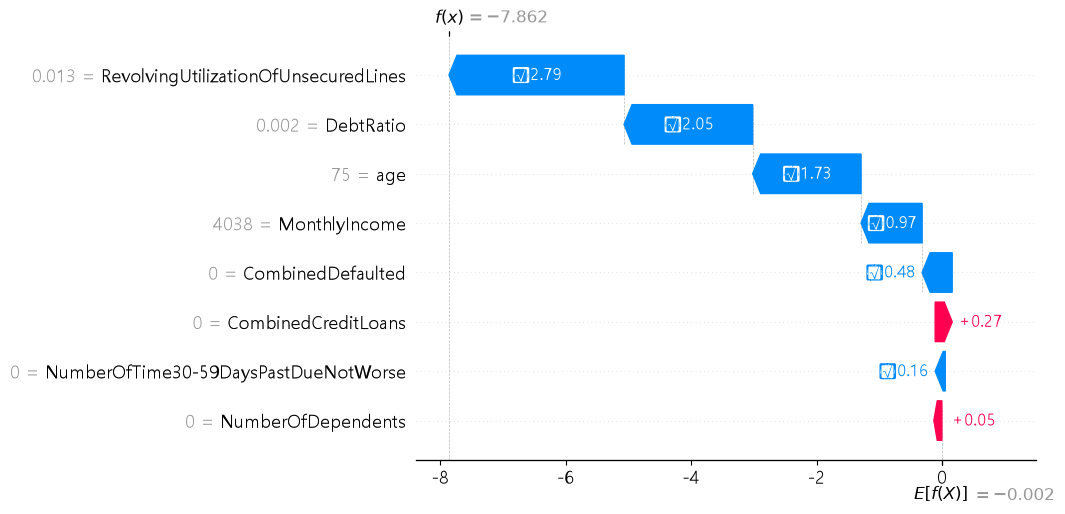

In [42]:
# [Phase 8-2] SHAP 국소적(Local) 해석: 개별 고객(정상 판정 고객 vs 부도 고위험 고객) 심사 근거 비교 (Waterfall Plot)
sample_probs = best_model.predict_proba(X_test_sample)[:, 1]
high_risk_idx = int(np.argmax(sample_probs))
low_risk_idx = int(np.argmin(sample_probs))

print(f"🔴 [고위험 부도 예측 고객 사례] 예측 부도 확률: {sample_probs[high_risk_idx]*100:.1f}% (실제 라벨: {Y_test.loc[X_test_sample.index[high_risk_idx]]})")
plt.figure(figsize=(10, 4.5))
shap.plots.waterfall(shap_explanation[high_risk_idx], show=True)

print(f"\n🟢 [저위험 정상 예측 고객 사례] 예측 부도 확률: {sample_probs[low_risk_idx]*100:.1f}% (실제 라벨: {Y_test.loc[X_test_sample.index[low_risk_idx]]})")
plt.figure(figsize=(10, 4.5))
shap.plots.waterfall(shap_explanation[low_risk_idx], show=True)

---
### 9. 최종 결론 및 비즈니스 인사이트 요약 (7분 발표 핵심 정리)

1. **데이터 진단 및 전처리 (`Lab 1 ~ Lab 3`)**:
   - `Give Me Some Credit` 데이터셋(150,000건, 8개 핵심 특성)은 **심각한 클래스 불균형($\text{IR} = 13.961$, 부도율 `6.68%`)**과 **비선형 중첩 구조(`PCA` 2D 확인)**, 그리고 재무 비율 변수의 극단적 왜도를 지니고 있다.
   - `Lab 3`의 특성 선택 실험을 통해, 도메인 파생변수(`CombinedDefaulted`, `CombinedCreditLoans`)를 포함한 8개 특성을 모두 활용할 때 트리 앙상블의 비선형 상호작용 학습력이 극대화됨을 확인하였다.
2. **평가지표 설계 및 불균형 해소 (`Lab 4 ~ Lab 5` & `NATE` 논문)**:
   - 원본 불균형 데이터에서는 다수 클래스 편향으로 인해 **`Accuracy`가 `93.3%`로 높게 나오는 착시 현상(정확도의 역설)**이 발생하며, 실제 부도 탐지율(`Recall`)은 `1% ~ 12%`에 그쳐 치명적인 **제2종 오류(Type II Error, False Negative)**를 초래한다.
   - 이를 해결하기 위해 리샘플링을 적용한 결과, 다수 클래스 정보를 대량 유실하는 언더샘플링(`NearMiss`, 빠른 학습 속도가 장점) 대비 모든 정보를 보존하는 **`SMOTE` 오버샘플링 + 비모수 트리 앙상블(`RF`, `GB`, `XGB`)** 조합이 압도적인 성능(`ROC-AUC`, `MCC`, `F1-Score`)과 부도 탐지율 향상을 달성하였다.
3. **딥러닝 잠재 특성 및 설명 가능한 AI (`Lab 6` & `NOTE/NATE` 논문)**:
   - `Lab 6`의 신경망(`MLP`)과 비선형 오토인코더(`NSA`) 잠재 특성을 통해 비선형 표현 학습의 유효성을 확인하였다.
   - 나아가 `SHAP TreeExplainer`를 통해 **`RevolvingUtilizationOfUnsecuredLines`(신용한도 소진율), `CombinedDefaulted`(중장기 연체 이력), `NumberOfTime30-59DaysPastDueNotWorse`(단기 연체 횟수), `age`(연령)** 등 핵심 위험 요인의 영향력 방향을 규명하고, 개별 대출 심사 고객에 대한 투명한 승인/거절 근거를 제시함으로써 **높은 예측력(Predictive Power)과 설명 가능성(Explainability)을 동시에 확보**하였다.